# AlphaFold distograms vs. elastic network models: the AK2 C-terminal tail

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/VesileHann/ak2-distogram-anm/blob/main/AK2_distogram_ANM.ipynb)

This notebook reproduces the core distogram analysis of
;
> Savaş *et al.* (2026). *Exploring the potential of AlphaFold distograms for predicting binding-induced hinge motions.* **FEBS Letters**.

and extends it with an **Anisotropic Network Model (ANM)** analysis to ask a simple question:

> *Can a classical elastic network model see the same flexibility that the AlphaFold distogram reveals?*

### Background in one paragraph

Adenylate kinase 2 (**AK2**) has a flexible C-terminal tail. When AK2 is alone (**apo**), the tail is coiled (helix-like); when it binds its partner **AIFM1** (**holo**), the tail stretches into a straight β-strand and stacks onto AIFM1. The distance between residues **230 and 233** is used as a marker of this change: **≈ 6 Å** means coiled (apo), **≈ 10 Å** means extended (holo).

AlphaFold predicts a single 3D structure, but internally it also outputs a **distogram**: for every residue pair, a probability distribution over 64 distance bins (≈ 2–22 Å). The paper shows that, even when AK2 is modelled *without* its partner, the 230–233 distogram contains a second, holo-like peak at ≈ 10 Å, while the final structure keeps only the apo state.

### What this notebook does

| Section | Question |
|---|---|
| 1–2 | Load the authors' public distogram data and average it per method |
| 3 | Detect apo / holo peaks automatically and quantify their probability mass |
| 4 | How consistent are individual AF2 models (seeds)? |
| 5 | What does ANM say about AK2's flexibility, using the crystal structure (PDB 2C9Y)? |
| 6 | What happens with the full-length AlphaFold model (tail included)? |
| 7 | Does the AlphaFold *structure* keep the holo-like state that the *distogram* shows? |
| 8 | Summary and limitations |

**Data source:** [CSB-KaracaLab/af-distogram-flexibility](https://github.com/CSB-KaracaLab/af-distogram-flexibility) (distograms), [RCSB PDB](https://www.rcsb.org/structure/2C9Y) (crystal structure), [AlphaFold DB](https://alphafold.ebi.ac.uk/entry/P54819) (AlphaFold model, UniProt P54819).

In [21]:
# Install ProDy (elastic network models, PDB parsing). Quiet mode keeps the output short.
!pip install -q prody

In [22]:
import glob
import json
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
import prody as pr

# ProDy prints a lot of DEBUG messages by default; keep only warnings and errors.
pr.confProDy(verbosity="warning")

INFO:.prody:ProDy is configured: verbosity='warning'


In [23]:
# Public distogram data for the AK2 residue pair 230-233 (from the paper's repository)
DATA_URL = ("https://raw.githubusercontent.com/CSB-KaracaLab/af-distogram-flexibility/"
            "main/data/distograms/AK2_distograms_res230_233.csv")

PAIR = (230, 233)          # marker residue pair (1-based, UniProt numbering)

# Reference distances for the two states (from the MD simulations in the paper)
APO_REF  = 6.0             # coiled tail, AK2 alone
HOLO_REF = 10.0            # extended tail, AK2 bound to AIFM1

# Distance windows used to measure how much probability sits in each state
APO_WINDOW  = (5.0, 7.5)
HOLO_WINDOW = (9.0, 11.5)

# Peak detection: a peak must rise at least this much above its surroundings.
# A fixed height threshold (e.g. 0.03) misses the small AF3 holo peak (~0.02),
# so prominence is a better criterion here.
PEAK_PROMINENCE = 0.005

# Elastic network model settings
PDB_ID     = "2C9Y"        # AK2 crystal structure
UNIPROT_ID = "P54819"      # human AK2, used to fetch the AlphaFold DB model
ANM_CUTOFF = 15.0          # Å; residues closer than this are connected by a spring
N_MODES    = 10            # number of normal modes to compute
N_SLOW     = 3             # number of slowest modes used for the fluctuation profile

# Figures are written here so they can be committed to the repository
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Load the distogram data

Each row of the CSV is one distance bin; each column (except the first) is the distogram of the 230–233 pair from one AlphaFold run. Column names encode the method, model and seed, e.g. `af2_model_1_seed_000`, `af3-seed0`, `afsample2_...`.

In [24]:
df = pd.read_csv(DATA_URL)
x_dist = df["Distance_Angstrom"]      # bin centres in Å

print(f"{len(df)} distance bins, {x_dist.min():.2f}–{x_dist.max():.2f} Å "
      f"(bin width ≈ {np.diff(x_dist).mean():.3f} Å)")
print(f"{df.shape[1] - 1} distograms in total")
df.iloc[:5, :4]

64 distance bins, 2.16–21.84 Å (bin width ≈ 0.312 Å)
2342 distograms in total


,Distance_Angstrom,af2_model_1_seed_000,af2_model_1_seed_001,af2_model_1_seed_002
0,2.15625,0.000003,0.000003,0.000003
1,2.46875,0.000002,0.000003,0.000003
2,2.78125,0.000010,0.000010,0.000010
3,3.09375,0.000026,0.000025,0.000024
4,3.40625,0.000067,0.000078,0.000078


In [38]:
# Sanity check: every distogram is a probability distribution, so each column should sum to ~1. A large deviation would mean we misread the file.
col_sums = df.drop(columns="Distance_Angstrom").sum()
print(f"Column sums: min = {col_sums.min():.3f}, max = {col_sums.max():.3f}")

Column sums: min = 0.999, max = 1.001


## 2. Average distogram per method

The file contains many runs per method (different models and random seeds). A single run can be noisy, so, as in the paper, we average all runs of a method. The prefixes below select the columns of each method.

In [26]:
METHOD_PREFIXES = {
    "AF2":        "af2_",
    "AF3":        "af3-",
    "AFsample2":  "afsample2",
    "AF3sample2": "af3sample2",
}

def columns_for(prefix):
    #Return all column names that belong to one method.
    return [c for c in df.columns if c.startswith(prefix)]

def method_mean(prefix):
    #Average distogram over all runs (columns) of one method.
    return df[columns_for(prefix)].mean(axis=1)

methods = {name: method_mean(prefix) for name, prefix in METHOD_PREFIXES.items()}

for name, prefix in METHOD_PREFIXES.items():
    print(f"{name:<11} {len(columns_for(prefix)):>4} runs averaged")

AF2           25 runs averaged
AF3           25 runs averaged
AFsample2    500 runs averaged
AF3sample2   500 runs averaged


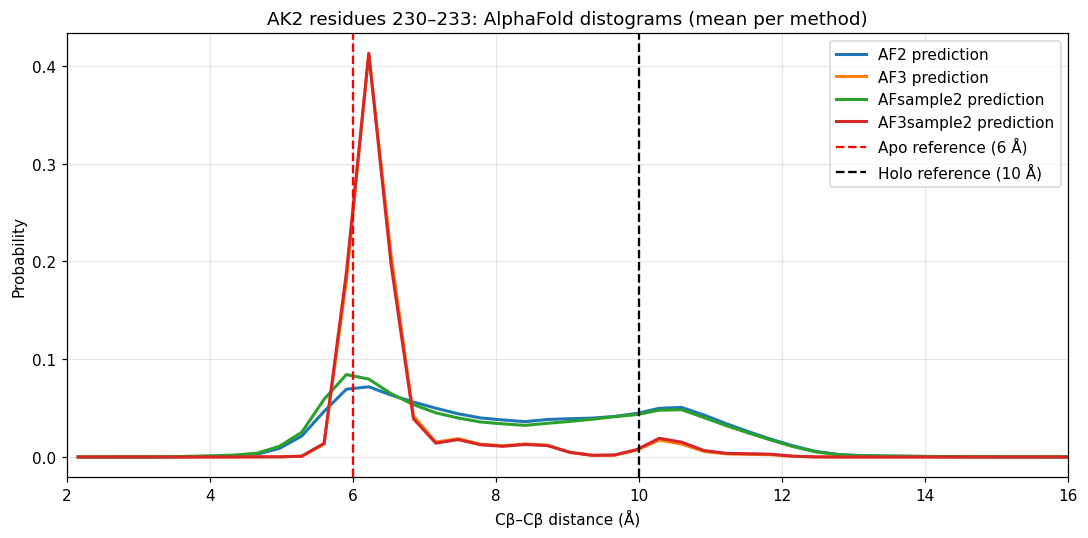

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))
for name, p in methods.items():
    ax.plot(x_dist, p, lw=2, label=f"{name} prediction")

ax.axvline(APO_REF,  color="red",   ls="--", label=f"Apo reference ({APO_REF:.0f} Å)")
ax.axvline(HOLO_REF, color="black", ls="--", label=f"Holo reference ({HOLO_REF:.0f} Å)")
ax.set(title=f"AK2 residues {PAIR[0]}–{PAIR[1]}: AlphaFold distograms (mean per method)",
       xlabel="Cβ–Cβ distance (Å)", ylabel="Probability", xlim=(2, 16))
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/01_distograms_per_method.png", dpi=200)
plt.show()

**Reading the plot.** All methods put most of the probability near 6 Å (coiled, apo tail). AF2 and AFsample2 also show a clear second bump near 10.5 Å (extended, holo-like tail); AF3 shows a much smaller one. AlphaFold was given **only AK2**, without AIFM1, so this second peak is the "hidden" bound-state signal described in the paper.

## 3. Automatic peak detection

Instead of reading peaks by eye, we detect them with `scipy.signal.find_peaks`. We also integrate the probability inside an apo window and a holo window, which gives a single number for "how much does the model believe in each state".

In [28]:
def find_distogram_peaks(p, prominence=PEAK_PROMINENCE):
    #Return (distance, probability) for every peak in a distogram
    idx, _ = find_peaks(p.to_numpy(), prominence=prominence)
    return [(x_dist.iloc[i], p.iloc[i]) for i in idx]

def window_mass(p, window):
    lo, hi = window
    return p[(x_dist >= lo) & (x_dist <= hi)].sum()

rows = []
for name, p in methods.items():
    peaks = find_distogram_peaks(p)
    rows.append({
        "method": name,
        "n_peaks": len(peaks),
        "peaks (Å, p)": ", ".join(f"{d:.2f} ({q:.3f})" for d, q in peaks),
        "P(apo window)":  round(window_mass(p, APO_WINDOW), 3),
        "P(holo window)": round(window_mass(p, HOLO_WINDOW), 3),
    })

peak_table = pd.DataFrame(rows).set_index("method")
peak_table

,n_peaks,"peaks (Å, p)",P(apo window),P(holo window)
method,,,,
AF2,2,"6.22 (0.072), 10.59 (0.051)",0.423,0.342
AF3,2,"6.22 (0.413), 10.28 (0.017)",0.889,0.055
AFsample2,2,"5.91 (0.084), 10.59 (0.048)",0.451,0.328
AF3sample2,2,"6.22 (0.413), 10.28 (0.019)",0.884,0.061


Every method has two peaks, one near 6 Å and one near 10.3–10.6 Å, matching the apo and holo references. The window masses show how differently the methods weigh the holo-like state: AF3 is much more confident in the apo state than AF2.

## 4. How consistent are individual AF2 runs?

An average can hide variation. Here every individual AF2 run is drawn as a thin line, with the mean on top, and we count how many runs show a holo-like peak on their own.

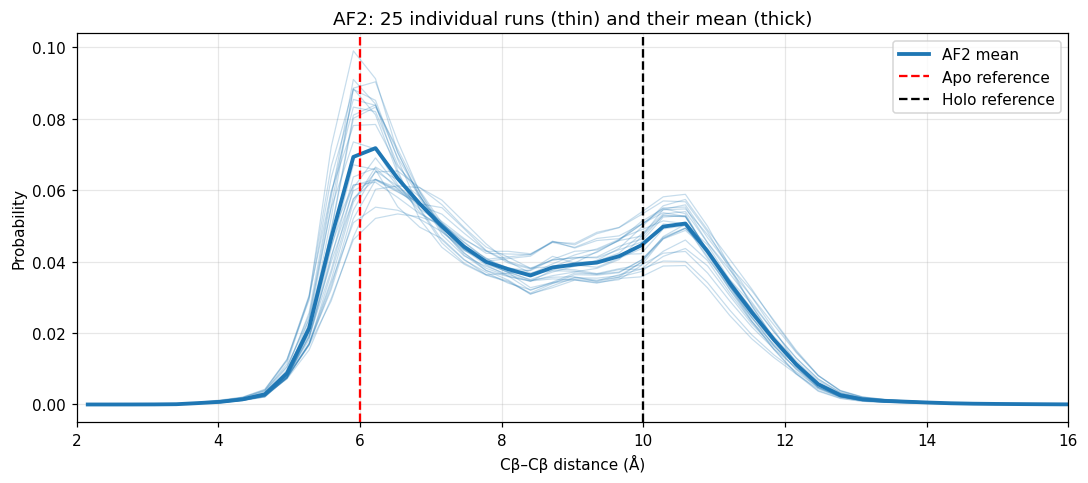

23/25 AF2 runs have their own peak in the holo window (9.0, 11.5) Å


In [29]:
af2_cols = columns_for(METHOD_PREFIXES["AF2"])

fig, ax = plt.subplots(figsize=(10, 4.5))
for c in af2_cols:
    ax.plot(x_dist, df[c], color="tab:blue", lw=0.8, alpha=0.25)
ax.plot(x_dist, methods["AF2"], color="tab:blue", lw=2.5, label="AF2 mean")
ax.axvline(APO_REF,  color="red",   ls="--", label="Apo reference")
ax.axvline(HOLO_REF, color="black", ls="--", label="Holo reference")
ax.set(title=f"AF2: {len(af2_cols)} individual runs (thin) and their mean (thick)",
       xlabel="Cβ–Cβ distance (Å)", ylabel="Probability", xlim=(2, 16))
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/02_af2_individual_runs.png", dpi=200)
plt.show()

# A run "sees" the holo state if it has a peak inside the holo window
n_holo = sum(
    any(HOLO_WINDOW[0] <= d <= HOLO_WINDOW[1] for d, _ in find_distogram_peaks(df[c]))
    for c in af2_cols
)
print(f"{n_holo}/{len(af2_cols)} AF2 runs have their own peak in the holo window {HOLO_WINDOW} Å")

## 5. Elastic network model on the crystal structure (PDB 2C9Y)

### What is ANM?

The **Anisotropic Network Model** treats a protein as a network of beads and springs:

1. every residue is a **node**, placed at its Cα atom;
2. any two residues closer than a cutoff (here 15 Å) are joined by an identical **spring**;
3. the network's stiffness is written as a 3N × 3N **Hessian** matrix;
4. its **eigenvectors** are the normal modes (directions of collective motion), and the modes with the **smallest eigenvalues** are the slowest, largest-scale motions, typically domain hinge motions.

From the slowest modes we compute each residue's **mean-square fluctuation**: a high value means that residue moves a lot in these collective motions. Values are relative, not absolute distances.

Important: in 2C9Y the flexible C-terminal tail is **not resolved**, which is exactly why the paper turned to AlphaFold.

In [30]:
def run_anm(calphas, name, cutoff=ANM_CUTOFF, n_modes=N_MODES, n_slow=N_SLOW):
    """Build an ANM on a set of Cα atoms and return (model, square fluctuations).
    The fluctuation profile is computed from the `n_slow` slowest non-trivial modes,
    which describe the largest collective motions.
    """
    anm = pr.ANM(name)
    anm.buildHessian(calphas, cutoff=cutoff)
    anm.calcModes(n_modes=n_modes)          # the 6 rigid-body modes are removed automatically
    return anm, pr.calcSqFlucts(anm[:n_slow])

crystal = pr.parsePDB(PDB_ID)
ca_xtal = crystal.select("calpha and chain A")
res_xtal = ca_xtal.getResnums()

print(f"{PDB_ID} chain A: residues {res_xtal.min()}–{res_xtal.max()} ({len(ca_xtal)} Cα atoms)")
for r in range(PAIR[0], PAIR[1] + 1):
    print(f"  residue {r}: {'present' if r in res_xtal else 'MISSING'}")

anm_xtal, fl_xtal = run_anm(ca_xtal, f"AK2 {PDB_ID}")

DEBUG:.prody:PDB file is found in working directory (2c9y.pdb.gz).
DEBUG:.prody:1878 atoms and 1 coordinate set(s) were parsed in 0.04s.
DEBUG:.prody:Hessian was built in 0.13s.


2C9Y chain A: residues 15–232 (218 Cα atoms)
  residue 230: present
  residue 231: present
  residue 232: present
  residue 233: MISSING


DEBUG:.prody:10 modes were calculated in 0.12s.


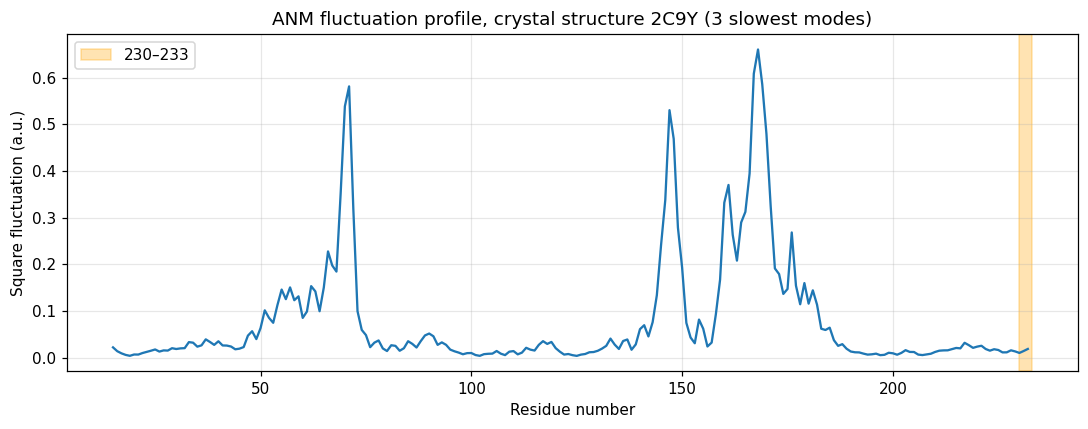

In [31]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(res_xtal, fl_xtal, lw=1.5, color="tab:blue")
ax.axvspan(PAIR[0], PAIR[1], color="orange", alpha=0.3, label=f"{PAIR[0]}–{PAIR[1]}")
ax.set(title=f"ANM fluctuation profile, crystal structure {PDB_ID} ({N_SLOW} slowest modes)",
       xlabel="Residue number", ylabel="Square fluctuation (a.u.)")
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/03_anm_crystal.png", dpi=200)
plt.show()

**Reading the plot.** ANM finds a rigid core and a few highly mobile regions (around residues ~55–70 and ~145–175). These are motions of the enzyme's own catalytic domains, unrelated to AIFM1 binding. At 230–233 the profile is flat: the crystal structure ends here, so ANM has no tail to move.

## 6. Elastic network model on the full-length AlphaFold model

The AlphaFold model contains the whole sequence, including both termini. We first check AlphaFold's per-residue confidence (**pLDDT**, stored in the B-factor column of AlphaFold PDB files), then run ANM on the full model, then on a version trimmed to the crystal's residue range.

If you ran ColabFold yourself, put its `rank_001` `.pdb` file next to this notebook and it will be used; otherwise the model is downloaded from the AlphaFold Database.

In [32]:
def get_alphafold_model(uniprot_id=UNIPROT_ID):
    #Use a local ColabFold/AlphaFold PDB if present, otherwise download from AlphaFold DB.
    local = sorted(set(glob.glob("*.pdb") + glob.glob("**/*rank_001*.pdb", recursive=True)))
    local = [f for f in local if PDB_ID.lower() not in f.lower()]
    if local:
        print("Using local AlphaFold model:", local[0])
        return local[0]

    api = f"https://alphafold.ebi.ac.uk/api/prediction/{uniprot_id}"
    info = json.load(urllib.request.urlopen(api))[0]
    path = f"AF-{uniprot_id}.pdb"
    urllib.request.urlretrieve(info["pdbUrl"], path)
    print("Downloaded from AlphaFold DB:", path)
    return path

af_file   = get_alphafold_model()
af_struct = pr.parsePDB(af_file)
ca_af     = af_struct.select("calpha")
res_af    = ca_af.getResnums()
plddt     = ca_af.getBetas()          # pLDDT is stored in the B-factor column

print(f"AlphaFold model: residues {res_af.min()}–{res_af.max()} ({len(ca_af)} Cα atoms)")

DEBUG:.prody:1854 atoms and 1 coordinate set(s) were parsed in 0.04s.


Using local AlphaFold model: AF-P54819.pdb
AlphaFold model: residues 1–239 (239 Cα atoms)


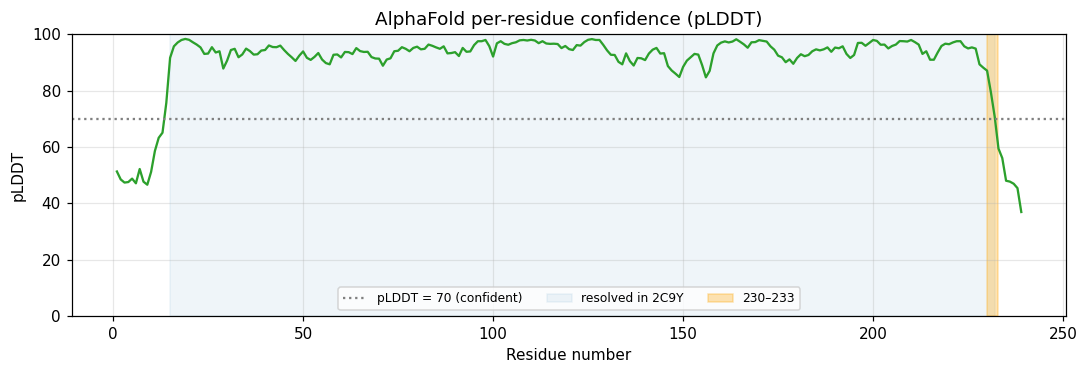

pLDDT of the first 15 residues: [51. 48. 47. 48. 49. 47. 52. 48. 47. 51. 59. 63. 65. 76. 92.]
pLDDT of the last 15 residues:  [95. 95. 95. 89. 88. 87. 79. 71. 59. 56. 48. 48. 47. 45. 37.]


In [33]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(res_af, plddt, color="tab:green", lw=1.5)
ax.axhline(70, color="grey", ls=":", label="pLDDT = 70 (confident)")
ax.axvspan(res_xtal.min(), res_xtal.max(), color="tab:blue", alpha=0.07,
           label=f"resolved in {PDB_ID}")
ax.axvspan(PAIR[0], PAIR[1], color="orange", alpha=0.3, label=f"{PAIR[0]}–{PAIR[1]}")
ax.set(title="AlphaFold per-residue confidence (pLDDT)",
       xlabel="Residue number", ylabel="pLDDT", ylim=(0, 100))
ax.legend(loc="lower center", ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/04_alphafold_plddt.png", dpi=200)
plt.show()

print("pLDDT of the first 15 residues:", plddt[:15].round(0))
print("pLDDT of the last 15 residues: ", plddt[-15:].round(0))

The regions missing from the crystal structure are also the regions where AlphaFold is least confident: both ends of the chain are flexible.

### 6a. ANM on the *full* AlphaFold model

Loosely packed termini have very few springs, so ANM lets them swing freely. The next cell shows what this does to the fluctuation profile.

DEBUG:.prody:Hessian was built in 0.31s.
DEBUG:.prody:10 modes were calculated in 0.84s.


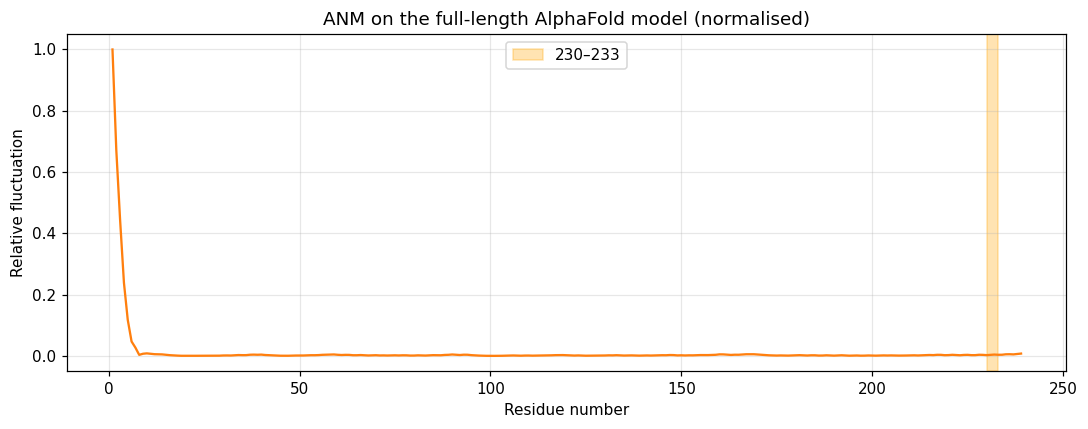

In [34]:
anm_af_full, fl_af_full = run_anm(ca_af, "AK2 AlphaFold (full)")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(res_af, fl_af_full / fl_af_full.max(), color="tab:orange", lw=1.5)
ax.axvspan(PAIR[0], PAIR[1], color="orange", alpha=0.3, label=f"{PAIR[0]}–{PAIR[1]}")
ax.set(title="ANM on the full-length AlphaFold model (normalised)",
       xlabel="Residue number", ylabel="Relative fluctuation")
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/05_anm_alphafold_full.png", dpi=200)
plt.show()

The dangling terminal residues take over the slowest modes, and every other region looks flat in comparison. ANM treats the tail as a **loose string**, not as a segment that switches between two defined shapes.

### 6b. ANM on the trimmed AlphaFold model vs. the crystal structure

To compare like with like, we keep only the residue range resolved in the crystal structure.

Trimmed AlphaFold model: residues 15–232


DEBUG:.prody:Hessian was built in 0.25s.
DEBUG:.prody:10 modes were calculated in 0.32s.


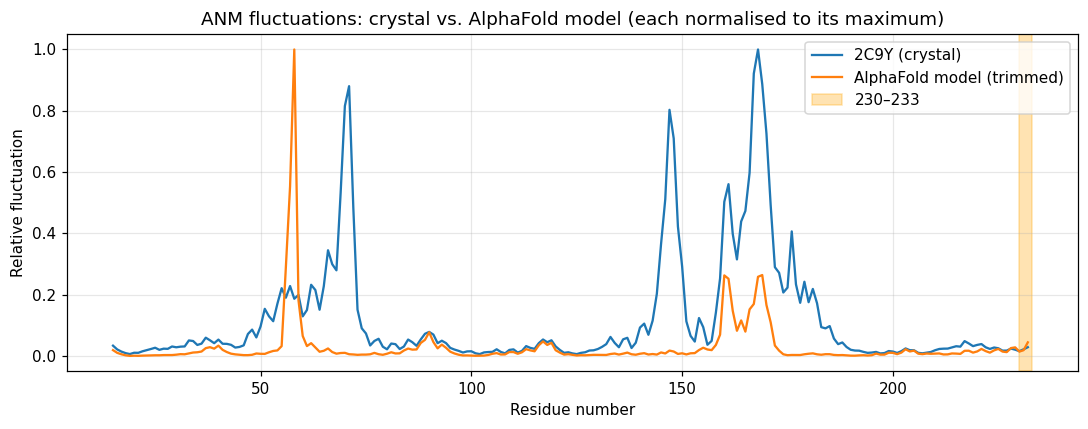

Correlation of the two fluctuation profiles: r = 0.34 (218 common residues)


In [35]:
start, end = int(res_xtal.min()), int(res_xtal.max())
ca_af_trim = af_struct.select(f"calpha and resnum >= {start} and resnum <= {end}")
res_af_trim = ca_af_trim.getResnums()
print(f"Trimmed AlphaFold model: residues {res_af_trim.min()}–{res_af_trim.max()}")

anm_af_trim, fl_af_trim = run_anm(ca_af_trim, "AK2 AlphaFold (trimmed)")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(res_xtal,    fl_xtal    / fl_xtal.max(),    lw=1.5, label=f"{PDB_ID} (crystal)")
ax.plot(res_af_trim, fl_af_trim / fl_af_trim.max(), lw=1.5, label="AlphaFold model (trimmed)")
ax.axvspan(PAIR[0], PAIR[1], color="orange", alpha=0.3, label=f"{PAIR[0]}–{PAIR[1]}")
ax.set(title="ANM fluctuations: crystal vs. AlphaFold model (each normalised to its maximum)",
       xlabel="Residue number", ylabel="Relative fluctuation")
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/06_anm_crystal_vs_alphafold.png", dpi=200)
plt.show()

# Pearson correlation between the two profiles on their common residues
common = np.intersect1d(res_xtal, res_af_trim)
a = fl_xtal[np.isin(res_xtal, common)]
b = fl_af_trim[np.isin(res_af_trim, common)]
print(f"Correlation of the two fluctuation profiles: r = {np.corrcoef(a, b)[0, 1]:.2f} "
      f"({len(common)} common residues)")

After trimming, both structures point to the same mobile regions, although the exact peak positions and heights differ. ANM depends on the single input structure it is given. In both cases the 230–233 region stays flat.

## 7. Does the AlphaFold *structure* keep the holo-like state?

The distogram shows two possible distances for 230–233. A 3D structure can only have one. Here we measure the actual Cβ–Cβ distance in the AlphaFold model (Cα for glycine, which has no Cβ).

In [36]:
def cb_coords(structure):
    """Map residue number -> Cβ coordinates (Cα for glycine).

    Filtering is done with NumPy rather than a ProDy selection string, because some
    ProDy/pyparsing versions fail on parenthesised selections such as
    "(name CB) or (name CA and resname GLY)".
    """
    coords = {}
    for name, resname, resnum, xyz in zip(structure.getNames(), structure.getResnames(),
                                          structure.getResnums(), structure.getCoords()):
        if name == "CB" or (name == "CA" and resname == "GLY"):
            coords[resnum] = xyz
    return coords

cb = cb_coords(af_struct)
i, j = PAIR
d = None
if i in cb and j in cb:
    d = np.linalg.norm(cb[i] - cb[j])
    state = "apo-like (coiled)" if abs(d - APO_REF) < abs(d - HOLO_REF) else "holo-like (extended)"
    print(f"AlphaFold model, residues {i}–{j}: {d:.2f} Å  ->  {state}")
else:
    print(f"Residue {i} or {j} is missing from the model; check the numbering.")

AlphaFold model, residues 230–233: 6.30 Å  ->  apo-like (coiled)


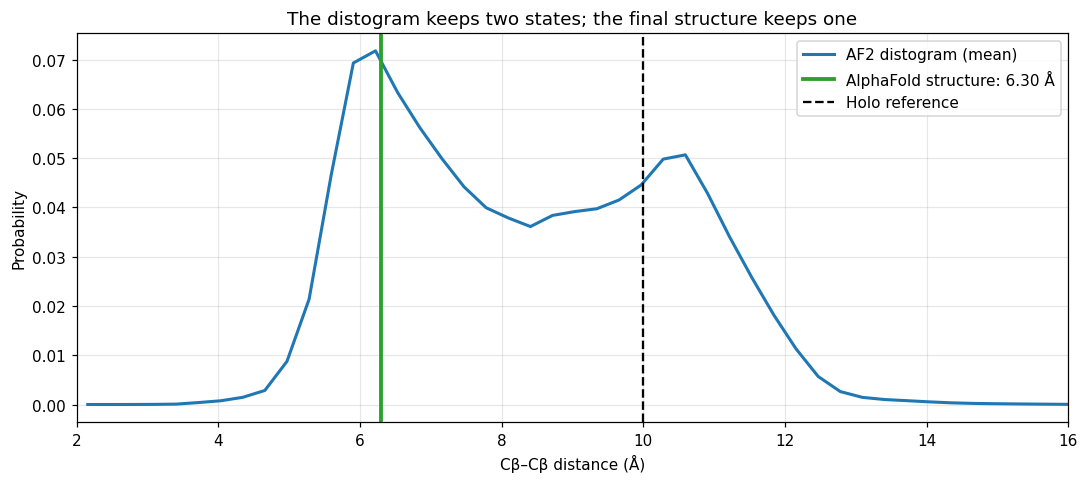

In [37]:
# Put the structure distance on top of the AF2 distogram for a direct visual comparison
assert d is not None, "Run the previous cell first (and check that both residues exist)."
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(x_dist, methods["AF2"], lw=2, label="AF2 distogram (mean)")
ax.axvline(d, color="tab:green", lw=2.5, label=f"AlphaFold structure: {d:.2f} Å")
ax.axvline(HOLO_REF, color="black", ls="--", label="Holo reference")
ax.set(title="The distogram keeps two states; the final structure keeps one",
       xlabel="Cβ–Cβ distance (Å)", ylabel="Probability", xlim=(2, 16))
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/07_distogram_vs_structure.png", dpi=200)
plt.show()

## 8. Summary

1. **The distogram encodes both states.** Averaged over runs, every AlphaFold variant tested has an apo peak (6 Å) and a holo-like peak (10.3–10.6 Å) for the 230–233 pair, although AlphaFold never saw AIFM1. The methods differ in how much weight they give the holo-like state (AF2 > AF3).
2. **The final structure keeps only one state.** The AlphaFold DB model places 230–233 at ≈ 6 Å, i.e. the apo state; the holo-like information exists only in the distogram.
3. **Classical ANM cannot describe the tail.** On the crystal structure the tail is missing; on the full AlphaFold model the flexible termini dominate the slowest modes as loose strings. In both cases ANM captures the enzyme's domain motions but not the tail's switch between two defined shapes.

Together these observations motivate combining the two views: using distogram information (for example peak multiplicity or distribution width) to inform the springs of an elastic network, so that flexibility visible in the distogram is reflected in the predicted motions.

### Limitations

- Only one residue pair (230–233) of one protein is analysed, using data released with the paper.
- ANM is a harmonic model around a single structure; it describes small fluctuations, not transitions between distinct conformations.
- ANM fluctuations are relative and depend on the cutoff and the number of modes used.
- Residue numbering is assumed to follow UniProt P54819 in all sources; a different construct would shift the marker pair.